# 2_obj_detection

Bản chuyển từ sample **5. Others/2_obj_detection.ipynb**. Chạy các ô theo thứ tự.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import math
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset, Subset
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

FULL = False  # True: dùng dữ liệu và số epoch theo sample
PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "HUONG_DAN.txt").is_file()), Path.cwd())
ROOT = PROJECT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(2018)
torch.set_num_threads(min(4, torch.get_num_threads()))
results = {}

In [2]:
def epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = correct = units = 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            out = model(x)
            if isinstance(criterion, nn.CrossEntropyLoss):
                assert out.argmax(1).shape == y.shape and y.dtype == torch.long
                correct += (out.argmax(1) == y).sum().item()
            else:
                assert out.shape == y.shape
            loss = criterion(out, y)
            if not torch.isfinite(loss):
                raise ValueError("Loss không hữu hạn")
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * y.numel()
            units += y.numel()
    return total_loss / units, correct / units

def fit(name, model, train, valid, criterion, opt, lr, epochs, batch,
        early=False, schedule=False, checkpoint=False, verbose=True):
    for layer in model.modules():
        if isinstance(layer, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    model.to(DEVICE)
    writer = None
    if checkpoint:
        from torch.utils.tensorboard import SummaryWriter
        writer = SummaryWriter("logs/" + name)
    optimizer = opt(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.1, patience=4, min_lr=1e-4,
        threshold=1e-4, threshold_mode="abs")
    loaders = [DataLoader(train, batch, shuffle=True), DataLoader(valid, batch)]
    best, stale = float("inf"), 0
    for step in range(1, epochs + 1):
        train_loss, _ = epoch(model, loaders[0], criterion, optimizer)
        val_loss, accuracy = epoch(model, loaders[1], criterion)
        if writer:
            writer.add_scalar("loss/train", train_loss, step)
            writer.add_scalar("loss/validation", val_loss, step)
            writer.add_scalar("accuracy/validation", accuracy, step)
        if val_loss < best:
            best, stale = val_loss, 0
            if checkpoint:
                torch.save(model.state_dict(), f"{name}_best.pt")
        else:
            stale += 1
        if schedule:
            scheduler.step(val_loss)
        if early and stale >= 5:
            break
    if writer:
        writer.close()
    if checkpoint:
        model.load_state_dict(torch.load(f"{name}_best.pt", map_location=DEVICE,
                                         weights_only=True))
        val_loss, accuracy = epoch(model, loaders[1], criterion)
    metric = accuracy if isinstance(criterion, nn.CrossEntropyLoss) else val_loss
    results[name] = (len(train), len(valid), step, val_loss, metric)
    if verbose:
        print(f"{name} | {step} epoch | train loss {train_loss:.5f} | "
              f"val loss {val_loss:.5f}", end="")
        if isinstance(criterion, nn.CrossEntropyLoss):
            print(f" | accuracy {accuracy:.2%}", end="")
        print()
    return model

Mạng tích chập học điểm từ −1 (nền) đến +1 (xe) cho ô ảnh RGB 64 × 64. Cùng trọng số đó sinh bản đồ nhiệt trên toàn cảnh. Ở chế độ nhanh, trọng số chỉ được thử với dữ liệu giả lập.

Kiểm tra bằng ô ảnh và nhãn giả lập
vehicle | 1 epoch | train loss 1.16703 | val loss 1.15450
Đúng theo dấu 2/4


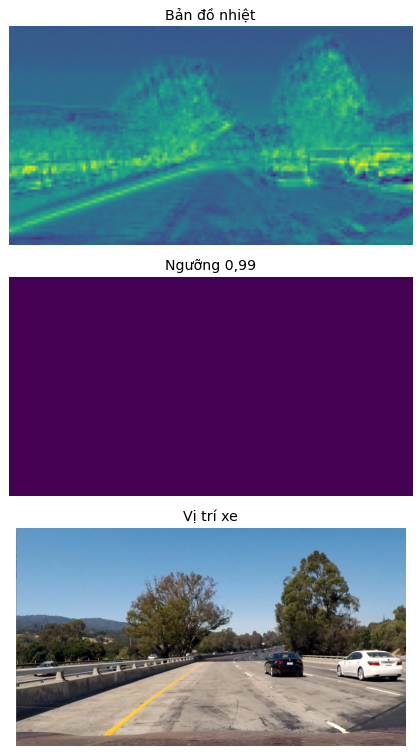

In [3]:
from PIL import ImageDraw
from sklearn.model_selection import train_test_split

class VehiclePatches(Dataset):
    def __init__(self, items):
        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        path, label = self.items[index]
        with Image.open(path) as img:
            x = transforms.PILToTensor()(img.convert("RGB")).float()
        assert x.shape == (3, 64, 64)
        return x, torch.tensor([label], dtype=torch.float32)

class VehicleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(nn.Conv2d(3, 10, 3, padding=1), nn.ReLU(),
            nn.Conv2d(10, 10, 3, padding=1), nn.ReLU(), nn.MaxPool2d(8),
            nn.Dropout(0.25), nn.Conv2d(10, 128, 8), nn.ReLU(), nn.Dropout(0.5),
            nn.Conv2d(128, 1, 1), nn.Tanh())

    def heatmap(self, x):
        return self.layers(x / 127.5 - 1)

    def forward(self, x):
        return self.heatmap(x).flatten(1)

if FULL:
    items = []
    for folder, label in [("vehicles", 1), ("non-vehicles", -1)]:
        paths = sorted((ROOT / "obj_detection" / folder).glob("*/*.png"))
        if not paths:
            raise FileNotFoundError(f"Thiếu ảnh trong {ROOT}/obj_detection/{folder}")
        items.extend((path, label) for path in paths)
    a, b = train_test_split(items, test_size=0.3, random_state=2018)
    train, valid = VehiclePatches(a), VehiclePatches(b)
else:
    print("Kiểm tra bằng ô ảnh và nhãn giả lập")
    def mock_patches():
        return TensorDataset(torch.randint(256, (4, 3, 64, 64)).float(),
                             torch.tensor([[-1.], [1.], [-1.], [1.]]))
    train, valid = mock_patches(), mock_patches()
model = fit("vehicle", VehicleNet(), train, valid, nn.MSELoss(), torch.optim.Adam,
            0.001, 5 if FULL else 1, 128)
with torch.inference_mode():
    correct = sum(((model(x.to(DEVICE)).cpu() > 0) == (y > 0)).sum().item()
                  for x, y in DataLoader(valid, 128))
print(f"Đúng theo dấu {correct}/{len(valid)}")
torch.save(model.state_dict(), "localize.pt")
detector = VehicleNet().to(DEVICE)
detector.load_state_dict(torch.load("localize.pt", map_location=DEVICE, weights_only=True))
detector.eval()
scene_path = next((p for p in [Path("test.jpg"), PROJECT / "test.jpg"] if p.exists()), None)
if scene_path is None:
    if FULL:
        raise FileNotFoundError("Đặt test.jpg cạnh notebook để chạy định vị")
    scene = Image.new("RGB", (160, 96))
    print("Dùng cảnh giả lập để kiểm tra kích thước.")
else:
    with Image.open(scene_path) as img:
        scene = img.convert("RGB")
with torch.inference_mode():
    hm = detector.heatmap(transforms.PILToTensor()(scene)[None].float().to(DEVICE))[0, 0].cpu()
selected = hm > 0.99
annotated = scene.copy()
draw = ImageDraw.Draw(annotated)
for y, x in selected.nonzero().tolist():
    draw.rectangle((8*x, 8*y, 8*x+63, 8*y+63), outline="lime", width=2)
fig, axes = plt.subplots(3, 1, figsize=(7, 9))
for ax, view, title in zip(axes, [hm, selected, annotated], ["Bản đồ nhiệt", "Ngưỡng 0,99", "Vị trí xe"]):
    ax.imshow(view)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()